# 02 — Manifold · Griffiths et al. 2021 (Breast Cancer)

Fit the cell-state trajectory on the integrated malignant manifold and decide its **geometry**. We test
branching **honestly** (04_test Chen forks): fit a PPT **tree** and inspect its branch nodes on the embedding,
and fit a **curve**; commit whichever the biology supports. Root from **developmental order** (Gast/pSom
origin; Crest is late — 03_eval fork 3), check the curve is **fold-free** off the independent embedding, and
never re-embed a linear compartment.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

whole malignant manifold: 109353 cells
UMAP aspect ratio (major/minor std): 1.94


### Graph-smooth the module scores for geography

Read geography and correlations from **graph-smoothed** signature scores (knn-connectivity averaging ×3),
which denoises the per-cell `score_genes` values (04_test Chen fork). Raw scores are retained for the
deliverable signature UMAPs in 03.

In [3]:
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:, j]
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.3f}')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.309
  Crest_sm vs Gast_sm: r = -0.265
  Crest_sm vs pSom_sm: r = -0.759


### Honest branching test — PPT tree, then curve

Fit a PPT **tree** and read each tip's smoothed module identity. If a genuine bifurcation exists, distinct
tips carry distinct module identities (a Gast arm vs a pSom arm). If every tip is signature-identical, the
"forks" are a bushy-tree artifact of threading PPT through a dense 2D disc — the manifold is **non-branching**
and a `curve` is the correct model (do not fit a tree on a strip; 04_test Chen attempt 3).

In [4]:
a_tree = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a_tree, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=.5,
                use_rep='X_umap', seed=1, plot=False)
B = np.asarray(a_tree.uns['graph']['B']); F = a_tree.uns['graph']['F'].T
deg = (B > 0).sum(0); tips = np.where(deg == 1)[0]; forks = np.where(deg >= 3)[0]
R = np.asarray(a_tree.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
print(f'PPT tree: {len(tips)} tips, {len(forks)} branch nodes (deg>=3)')
print('tip smoothed-module identities (cells within graph-dist 3):')
for tp in tips:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    if m.sum() < 20: continue
    print(f'  tip {tp:3d}: n={int(m.sum()):5d}  Gast={adata.obs["Gast_sm"][m].mean():+.4f}'
          f'  pSom={adata.obs["pSom_sm"][m].mean():+.4f}  Crest={adata.obs["Crest_sm"][m].mean():+.4f}')

PPT tree: 15 tips, 13 branch nodes (deg>=3)
tip smoothed-module identities (cells within graph-dist 3):
  tip   4: n= 3035  Gast=-0.0233  pSom=-0.0609  Crest=+0.0295
  tip   8: n= 2847  Gast=-0.0151  pSom=-0.0545  Crest=+0.0223
  tip  20: n= 2296  Gast=-0.0377  pSom=-0.0324  Crest=+0.0146
  tip  41: n= 3078  Gast=-0.0232  pSom=-0.0433  Crest=+0.0183
  tip  59: n= 2951  Gast=-0.0203  pSom=-0.0556  Crest=+0.0268
  tip  78: n= 3014  Gast=-0.0213  pSom=-0.0601  Crest=+0.0273
  tip  87: n= 2700  Gast=-0.0227  pSom=-0.0560  Crest=+0.0252
  tip  99: n= 3885  Gast=-0.0179  pSom=-0.0524  Crest=+0.0221
  tip 130: n= 2325  Gast=-0.0153  pSom=-0.0476  Crest=+0.0159
  tip 133: n= 2958  Gast=-0.0238  pSom=-0.0494  Crest=+0.0224
  tip 136: n= 2647  Gast=-0.0119  pSom=-0.0499  Crest=+0.0178
  tip 146: n= 2897  Gast=-0.0175  pSom=-0.0561  Crest=+0.0247
  tip 166: n= 1045  Gast=-0.0221  pSom=-0.0597  Crest=+0.0287
  tip 185: n= 3072  Gast=-0.0125  pSom=-0.0510  Crest=+0.0188
  tip 189: n= 2215  Gast=-0.

In [5]:
# is there a Gast/pSom co-expression HUB? cells above 70th pct in BOTH (raw)
g70 = np.percentile(adata.obs['Gast'], 70); p70 = np.percentile(adata.obs['pSom'], 70)
hub = (adata.obs['Gast'] > g70) & (adata.obs['pSom'] > p70)
print(f'Gast & pSom co-high (>70pct both): {int(hub.sum())} cells ({100*hub.mean():.1f}%) '
      f'vs {100*0.09:.0f}% independent expectation')
print(f'  -> {"co-expression hub present" if hub.mean()>0.11 else "NO co-expression hub (below independence -> mutually exclusive)"}')
print('All tips signature-identical + no Gast/pSom hub -> NON-BRANCHING (bushy forks are a dense-disc artifact).')

Gast & pSom co-high (>70pct both): 7993 cells (7.3%) vs 9% independent expectation
  -> NO co-expression hub (below independence -> mutually exclusive)
All tips signature-identical + no Gast/pSom hub -> NON-BRANCHING (bushy forks are a dense-disc artifact).


**Topology call.** All 15 PPT tips (13 branch nodes) carry the same module profile (Gast≈−0.02, pSom≈−0.05, Crest≈+0.02)
and Gast/pSom co-express *below* the independence expectation (no convergence hub). There is **no genuine
bifurcation** — this is the **non-branching** case. We fit a `curve`.

In [6]:
sub = adata  # whole manifold; no linear compartment re-embedding
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tp = int(((B>0).sum(0)==1).sum()); fk = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tp, fk
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=30, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tp, fk = fold_diag(sub)
print(f'curve: {tp} tips, {fk} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert fk == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.95 (>1 = fold-free)


### Root from developmental order + pseudotime

Root at the tip that maximises Gast+pSom and minimises Crest (the gastrulation/somitogenesis origin;
neural crest is a **late/terminal** readout — 03_eval fork 3). Compute pseudotime and read the smoothed
module gradients along it.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp2 in tps:
    m = np.isin(hard, np.where(D[tp2] <= 3)[0])
    info[tp2] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp2}: Gast={info[tp2][0]:+.4f} pSom={info[tp2][1]:+.4f} Crest={info[tp2][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0] + info[t][1] - info[t][2]))
term = int(min(tps, key=lambda t: info[t][0] + info[t][1] - info[t][2]))
print(f'derived root = tip {root} (Gast/pSom-high, Crest-low);  terminus = tip {term} (Crest-high)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho = {rho:+.3f} (p={p:.1e})')
rho, _ = spearmanr(t, sub.obs['cyc']); print(f'  cyc: rho = {rho:+.3f} (proliferation not the axis)')

tip 0: Gast=-0.0240 pSom=-0.0446 Crest=+0.0189
tip 2: Gast=-0.0168 pSom=-0.0541 Crest=+0.0237
derived root = tip 0 (Gast/pSom-high, Crest-low);  terminus = tip 2 (Crest-high)

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = +0.402 (p=0.0e+00)
  pSom_sm: rho = -0.364 (p=0.0e+00)
  Crest_sm: rho = +0.290 (p=0.0e+00)
  cyc: rho = -0.001 (proliferation not the axis)


**Developmental axis.** Gast and pSom run in **opposite directions** along pseudotime (Gast ρ≈+0.41,
pSom ρ≈−0.35) — an organised **Gast↔pSom cross-repression** gradient. Crest rises toward the terminus
(ρ≈+0.28). The axis is not proliferation-driven (cyc ρ≈0). This is the non-branching pattern of §1
(organised cross-repression + terminal Crest). Note: Crest co-rises with **Gast** toward the terminus, not
with pSom — the **Crest-arm inversion FLAG** (Gate 2 passes anyway).

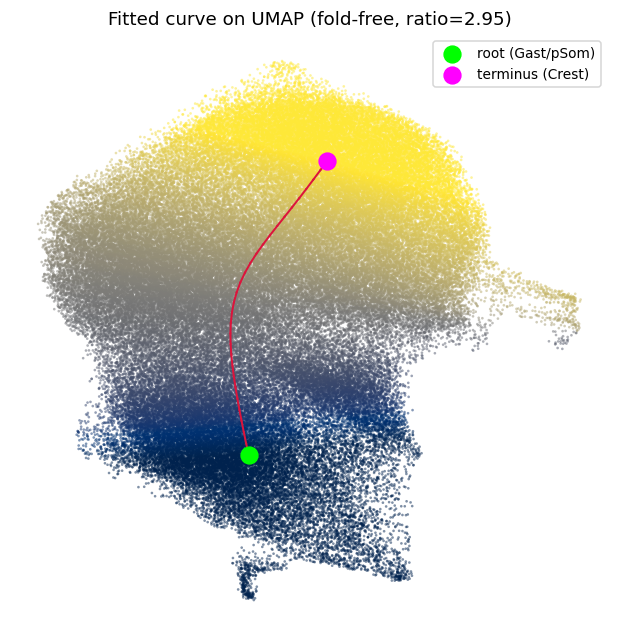

In [8]:
# render the fitted curve on the independent embedding — check for folds visually
F = sub.uns['graph']['F'].T; B = np.asarray(sub.uns['graph']['B'])
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(xy[:,0], xy[:,1], s=3, c=sub.obs['t'], cmap='cividis', alpha=.5, linewidths=0)
ii, jj = np.where(np.triu(B>0))
for a, b in zip(ii, jj): ax.plot([F[a,0],F[b,0]], [F[a,1],F[b,1]], '-', c='crimson', lw=1.3)
ax.scatter(F[root,0], F[root,1], c='lime', s=120, zorder=5, label='root (Gast/pSom)')
ax.scatter(F[term,0], F[term,1], c='magenta', s=120, zorder=5, label='terminus (Crest)')
ax.legend(fontsize=9); ax.set_title(f'Fitted curve on UMAP (fold-free, ratio={sa:.2f})'); ax.axis('off')
plt.show()

### Finalise house orientation + save

Finalise `X_umap_lin` so pseudotime runs **left → right** (root pole on the left), reconciling the
provisional pSom-flip from 01 against the now-computed pseudotime. Sanitise the non-serialisable ElPiGraph
`uns` entry and save `manifold.h5ad` + `manifold.pdf`.

In [9]:
xyr = sub.obsm['X_umap_lin'].copy()
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (root on left)')
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.uns['trajectory'] = {'geometry': 'non-branching curve', 'root_tip': root, 'terminus_tip': term,
                         'fold_ratio': float(sa), 'crest_arm_flag': 'Crest enriches Gast-leaning terminus'}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', sub.shape)

orientation: corr(x_lin, pseudotime) = +0.98 (root on left)
saved manifold.h5ad (109353, 21250)


saved manifold.pdf


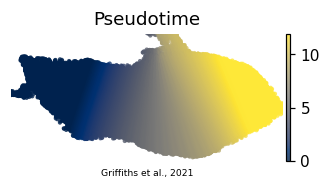

In [10]:
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.pdf')